# Section 7: Recommender Systems from Implicit Feedback

**What you'll learn**
- Turn MovieLens ratings into a watch matrix with no labels
- Hold out each user's last movies and grade with recall@10 and NDCG@10
- Beat a popularity baseline with item similarity
- Learn user and item factors with implicit ALS
- Solve EASE, a linear autoencoder over items, in closed form
- Train SASRec, a small transformer that predicts the next movie
- Find "more like this" movies from learned item vectors

## Setup
- Slides 1-2

In [1]:
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import implicit
import torch
from torch import nn
from sklearn.metrics.pairwise import cosine_similarity
from threadpoolctl import threadpool_limits

## Loading MovieLens 1M
- One million ratings from 6,040 users on about 3,700 movies, with timestamps

In [2]:
urllib.request.urlretrieve(
    "https://files.grouplens.org/datasets/movielens/ml-1m.zip", "ml-1m.zip")
z = zipfile.ZipFile("ml-1m.zip")
z.namelist()

['ml-1m/',
 'ml-1m/movies.dat',
 'ml-1m/ratings.dat',
 'ml-1m/README',
 'ml-1m/users.dat']

In [3]:
ratings = pd.read_csv(z.open("ml-1m/ratings.dat"), sep="::", engine="python",
                      names=["user", "item", "rating", "ts"])
ratings.head()

,user,item,rating,ts
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [4]:
movies = pd.read_csv(z.open("ml-1m/movies.dat"), sep="::", engine="python",
                     names=["item", "title", "genres"], encoding="latin-1")
movies.head()

,item,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


## Ratings as Implicit Feedback
- Slide 3
- Keep only who watched what; the star rating is dropped
- Every user has at least 20 movies

In [5]:
ratings.groupby("user").size().describe()

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64

- Number users and movies 0, 1, 2, ... so they can index rows and columns

In [6]:
ratings["u"] = ratings["user"].astype("category").cat.codes.astype(int)
items = ratings["item"].astype("category")
ratings["i"] = items.cat.codes.astype(int)
titles = movies.set_index("item").loc[items.cat.categories, "title"].to_numpy()
n_users, n_items = ratings["u"].max() + 1, ratings["i"].max() + 1
n_users, n_items

(np.int64(6040), np.int64(3706))

## Holding Out Each User's Last 10 Movies
- Slide 4
- Train on the past, predict the future, like a real system

In [7]:
ratings = ratings.sort_values(["u", "ts"], kind="stable")
ratings["from_end"] = ratings.groupby("u").cumcount(ascending=False)
train = ratings[ratings["from_end"] >= 10]
test = ratings[ratings["from_end"] < 10]
len(train), len(test)

(939809, 60400)

## The Watch Matrix
- Slide 5

In [8]:
X = sp.csr_matrix((np.ones(len(train), dtype="float32"), (train["u"], train["i"])),
                  shape=(n_users, n_items))
X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 939809 stored elements and shape (6040, 3706)>

- Share of the matrix that is filled

In [9]:
X.nnz / (n_users * n_items)

np.float64(0.04198529858507593)

## Grading a Recommender
- Slide 6
- One function, used for every model: hide movies already watched, take the top 10
- Recall@10: share of the 10 held-out movies in the top 10
- NDCG@10: the same, with more credit near the top of the list

In [10]:
truth = sp.csr_matrix((np.ones(len(test)), (test["u"], test["i"])),
                      shape=(n_users, n_items)).toarray() > 0
discount = 1 / np.log2(np.arange(2, 12))

def evaluate(scores):
    scores = np.array(scores, dtype="float32")
    scores[X.nonzero()] = -np.inf
    top = np.argsort(-scores, axis=1)[:, :10]
    hits = np.take_along_axis(truth, top, axis=1)
    return {"recall@10": hits.mean(),
            "ndcg@10": (hits * discount).sum(axis=1).mean() / discount.sum()}

## Popularity Baseline
- Slide 7
- Everyone gets the most watched movies they have not seen

In [11]:
popularity = np.asarray(X.sum(axis=0)).ravel()
results = {"Popularity": evaluate(np.tile(popularity, (n_users, 1)))}
results["Popularity"]

{'recall@10': np.float64(0.04105960264900662),
 'ndcg@10': np.float64(0.04444575137725266)}

In [12]:
titles[np.argsort(-popularity)[:10]]

array(['American Beauty (1999)',
       'Star Wars: Episode V - The Empire Strikes Back (1980)',
       'Star Wars: Episode IV - A New Hope (1977)',
       'Star Wars: Episode VI - Return of the Jedi (1983)',
       'Terminator 2: Judgment Day (1991)', 'Jurassic Park (1993)',
       'Saving Private Ryan (1998)', 'Back to the Future (1985)',
       'Matrix, The (1999)', 'Silence of the Lambs, The (1991)'],
      dtype=object)

## Item Similarity
- Slide 8
- Two movies are similar when the same people watched them
- Score = sum of similarities to everything the user watched

In [13]:
similarity = cosine_similarity(X.T)
np.fill_diagonal(similarity, 0)
results["Item similarity"] = evaluate(X @ similarity)
results["Item similarity"]

{'recall@10': np.float64(0.06456953642384106),
 'ndcg@10': np.float64(0.0697531447863223)}

## Implicit ALS
- Slides 9-10
- Factor the watch matrix into user vectors and item vectors
- Score = dot product of a user vector and an item vector
- implicit asks for one BLAS thread; it runs its own threads

In [14]:
threadpool_limits(1, "blas")
als = implicit.als.AlternatingLeastSquares(factors=64)
als.fit(X, show_progress=False)

In [15]:
als.user_factors.shape, als.item_factors.shape

((6040, 64), (3706, 64))

In [16]:
results["ALS"] = evaluate(als.user_factors @ als.item_factors.T)
results["ALS"]

{'recall@10': np.float64(0.07314569536423841),
 'ndcg@10': np.float64(0.0758611753254394)}

- More factors are not always better

In [17]:
for factors in [16, 32, 128]:
    model = implicit.als.AlternatingLeastSquares(factors=factors)
    model.fit(X, show_progress=False)
    print(factors, evaluate(model.user_factors @ model.item_factors.T))

16 {'recall@10': np.float64(0.0661092715231788), 'ndcg@10': np.float64(0.06920803872201782)}


32 {'recall@10': np.float64(0.07167218543046358), 'ndcg@10': np.float64(0.07526787574217925)}


128 {'recall@10': np.float64(0.06943708609271523), 'ndcg@10': np.float64(0.07236072604329763)}


## Recommendations for One User

In [18]:
user = 0
titles[train[train["u"] == user]["i"].to_numpy()[-10:]]

array(['Toy Story 2 (1999)', 'Airplane! (1980)', 'Pleasantville (1998)',
       'Dumbo (1941)', 'Princess Bride, The (1987)',
       'Snow White and the Seven Dwarfs (1937)',
       'Miracle on 34th Street (1947)', 'Ponette (1996)',
       "Schindler's List (1993)", 'Beauty and the Beast (1991)'],
      dtype=object)

In [19]:
ids, scores = als.recommend(user, X[user])
titles[ids]

array(['Star Wars: Episode V - The Empire Strikes Back (1980)',
       'Toy Story (1995)', 'Shawshank Redemption, The (1994)',
       'Amadeus (1984)', 'Lion King, The (1994)',
       'Raiders of the Lost Ark (1981)', 'Fantasia (1940)',
       'Aladdin (1992)',
       'Star Wars: Episode VI - Return of the Jedi (1983)',
       'Stand by Me (1986)'], dtype=object)

In [20]:
titles[test[test["u"] == user]["i"].to_numpy()]

array(['Tarzan (1999)', 'Close Shave, A (1995)', 'Aladdin (1992)',
       'Toy Story (1995)', "Bug's Life, A (1998)", 'Antz (1998)',
       'Hunchback of Notre Dame, The (1996)', 'Hercules (1997)',
       'Mulan (1998)', 'Pocahontas (1995)'], dtype=object)

## More Like This
- Slide 11
- Nearest item vectors

In [21]:
toy_story = np.where(titles == "Toy Story (1995)")[0][0]
ids, scores = als.similar_items(toy_story)
titles[ids]

array(['Toy Story (1995)', 'Toy Story 2 (1999)', 'Aladdin (1992)',
       'Babe (1995)', "Bug's Life, A (1998)", 'Groundhog Day (1993)',
       'Tarzan (1999)', 'Beauty and the Beast (1991)',
       'Lion King, The (1994)', 'Mulan (1998)'], dtype=object)

## EASE
- Slide 12
- A linear autoencoder over items: predict each movie from all the others
- Closed form: one matrix inverse, one setting `lam`

In [22]:
lam = 500
Xd = X.toarray()
P = np.linalg.inv(Xd.T @ Xd + lam * np.eye(n_items))
B = -P / np.diag(P)
np.fill_diagonal(B, 0)
results["EASE"] = evaluate(Xd @ B)
results["EASE"]

{'recall@10': np.float64(0.07665562913907285),
 'ndcg@10': np.float64(0.08044548847038413)}

## SASRec: Predicting the Next Movie
- Slides 13-15
- Each user's history as a sequence, oldest first
- Last 200 movies, padded on the left with the id `n_items`

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"
L = 200
seqs = np.full((n_users, L + 1), n_items)
for u, history in train.groupby("u")["i"]:
    history = history.to_numpy()[-(L + 1):]
    seqs[u, -len(history):] = history
seqs = torch.tensor(seqs, device=device)
seqs[0, -10:]

tensor([2898, 2586, 2128,  964, 1107,  580, 2205, 1421,  513,  581],
       device='cuda:0')

- Item embeddings plus position embeddings, two causal transformer layers
- The output at each position scores every movie as the next one

In [24]:
class SASRec(nn.Module):
    def __init__(self, n_items, d=64):
        super().__init__()
        self.item = nn.Embedding(n_items + 1, d, padding_idx=n_items)
        self.pos = nn.Embedding(L, d)
        layer = nn.TransformerEncoderLayer(d, nhead=2, dim_feedforward=4 * d,
                                           dropout=0.2, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)

    def forward(self, x):
        h = self.item(x) + self.pos.weight
        mask = nn.Transformer.generate_square_subsequent_mask(L, device=x.device)
        return self.encoder(h, mask=mask, is_causal=True) @ self.item.weight[:-1].T

sasrec = SASRec(n_items).to(device)
sum(p.numel() for p in sasrec.parameters())

350016

- Input: positions 0 to 199; target: positions 1 to 200, the next movie each time
- Padding is ignored in the loss

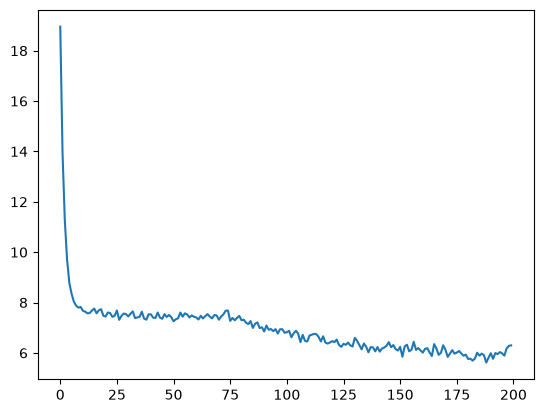

In [25]:
optimizer = torch.optim.Adam(sasrec.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(ignore_index=n_items)
losses = []
for epoch in range(200):
    sasrec.train()
    for batch in torch.randperm(n_users, device=device).split(128):
        logits = sasrec(seqs[batch, :-1])
        loss = loss_fn(logits.reshape(-1, n_items), seqs[batch, 1:].reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    losses.append(loss.item())
plt.plot(losses)

- Score: feed the last 200 movies, read the output at the final position

In [26]:
sasrec.eval()
with torch.no_grad():
    scores = torch.cat([sasrec(seqs[batch, 1:])[:, -1]
                        for batch in torch.arange(n_users, device=device).split(512)])
results["SASRec"] = evaluate(scores.cpu().numpy())
results["SASRec"]

{'recall@10': np.float64(0.1591390728476821),
 'ndcg@10': np.float64(0.17379526683197136)}

## Comparing the Recommenders
- Slides 16-17

In [27]:
pd.DataFrame(results).T

,recall@10,ndcg@10
Popularity,0.041060,0.044446
Item similarity,0.064570,0.069753
ALS,0.073146,0.075861
EASE,0.076656,0.080445
SASRec,0.159139,0.173795


## Lab: Your Own Watch History
- Pick a few movies you like, oldest first, and ask SASRec what comes next

In [28]:
mine = ["Toy Story (1995)", "Aladdin (1992)", "Lion King, The (1994)", "Mulan (1998)"]
ids = [np.where(titles == m)[0][0] for m in mine]
x = torch.full((1, L), n_items, device=device)
x[0, -len(ids):] = torch.tensor(ids, device=device)
with torch.no_grad():
    next_scores = sasrec(x)[0, -1]
next_scores[ids] = -np.inf
titles[next_scores.topk(10).indices.cpu().numpy()]

array(['Antz (1998)', 'Tarzan (1999)', 'Hercules (1997)',
       "Bug's Life, A (1998)", 'Beauty and the Beast (1991)',
       'James and the Giant Peach (1996)',
       'South Park: Bigger, Longer and Uncut (1999)',
       'Hunchback of Notre Dame, The (1996)', 'Anastasia (1997)',
       'Iron Giant, The (1999)'], dtype=object)

- Swap in a different taste, such as horror or westerns

## Wrap-Up
- Slides 18-20